# 02. Exploratory analysis

This notebook reproduces `docs/03_exploratory_analysis.md`. Only the training part of the corpus is read, so that no observation of the test set can influence the modelling choices.

In [1]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def run_tests(*files):
    result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", *files], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout.strip().splitlines()[-1])

In [2]:
import matplotlib.pyplot as plt

from hatari.analysis.eda import distinctive_words, indicator_rates, load_training, shape
from hatari.text.preprocessing import mask_entities

training = load_training()
display(training.groupby(["language", "suspicious"]).size().rename("messages").to_frame())

messages
language suspicious          
en       False           3976
         True             836
fr       False             47
         True              70

## 1. Message shape

In [3]:
display(shape(training))

characters  words  uppercase_share
language suspicious                                    
en       False             53.0   11.0            0.045
         True             145.0   24.0            0.144
fr       False            110.0   17.0            0.046
         True             150.5   22.0            0.026

**Finding.** Suspicious English messages are almost three times longer than legitimate ones and use three times more capitals. The French synthetic texts do not share the capital pattern.

## 2. Simple indicators

link  phone_number  money  any_digit  free_or_win  urgency  code_or_password
language suspicious                                                                               
en       False       0.003         0.001  0.006      0.162        0.020    0.090             0.002
         True        0.206         0.616  0.331      0.940        0.348    0.325             0.041
fr       False       0.000         0.000  0.000      0.745        0.000    0.021             0.000
         True        0.000         0.000  0.000      0.000        0.000    0.114             0.129

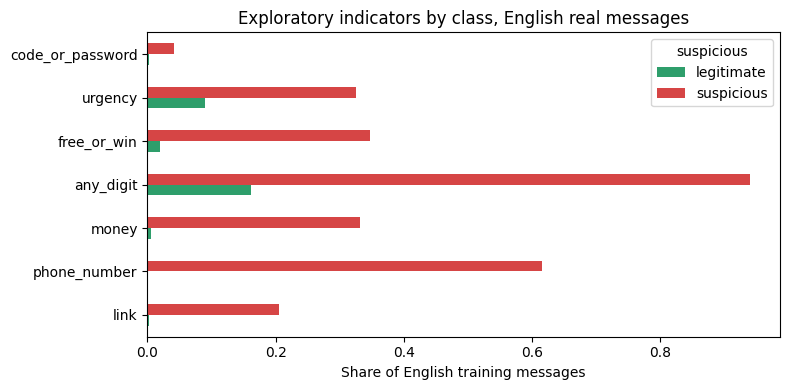

In [4]:
rates = indicator_rates(training)
display(rates)
english = rates.loc["en"].T.rename(columns={False: "legitimate", True: "suspicious"})
axis = english.plot.barh(figsize=(8, 4), color=["#2E9E6B", "#D64545"])
axis.set_xlabel("Share of English training messages")
axis.set_title("Exploratory indicators by class, English real messages")
plt.tight_layout()
plt.show()

**Findings**

- In English, phone numbers, digits, links and money are strong signs of suspicious messages, so preprocessing must not remove them.
- The French synthetic suspicious texts contain no link, number, amount or digit, while their legitimate texts contain times. A model trained on them alone would learn that digits mean legitimate.

## 3. Distinctive words

In [5]:
for language, part in training.groupby("language"):
    words = distinctive_words(part, minimum=15 if language == "en" else 5)
    print(language, "suspicious:", ", ".join(words["suspicious"]))
    print(language, "legitimate:", ", ".join(words["legitimate"]))

en suspicious: claim, prize, won, guaranteed, http, awarded, ppm, cs, valid, uk, tone, pobox, winner, ringtone, kyc
en legitimate: gt, lt, i'll, he, lor, ü, later, too, she, doing, happy, said, let, morning, lol
fr suspicious: une, ne, offre, avant, vos, appareil, sur, ouvrez, lien, contactez, alerte, service, recevoir, prévu, payez
fr legitimate: bientôt, bien, réservation, confirmée, enregistrée, je, merci, h, vers, retour, tu, et, est, à, bonjour


**Findings**

- English suspicious words come from British premium-rate spam of the 2000s, such as ringtone, ppm and pobox.
- The legitimate words gt and lt are HTML entities left by the collection of UCI, an artefact that reveals the label. They are decoded by `normalize`.

In [6]:
entities = training["text"].str.contains(r"&lt;|&gt;|&amp;", regex=True)
display(pd.crosstab(entities, training["suspicious"]).rename_axis(index="contains an HTML entity"))

suspicious,False,True
contains an HTML entity,,
False,3799,906
True,224,0


## 4. Effect of entity masking on two training messages

In [7]:
examples = training[training["suspicious"] & (training["language"] == "en")]["text"].head(2)
for text in examples:
    print("original:", text)
    print("masked:  ", mask_entities(text))
    print()

original: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
masked:   FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, xmoneyx to rcv

original: WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
masked:   WINNER!! As a valued network customer you have been selected to receivea xmoneyx prize reward! To claim call xphonex . Claim code KL341. Valid 12 hours only.

